In [1]:
#CELL 1 — Imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, roc_auc_score, roc_curve
from imblearn.over_sampling import SMOTE
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, Dense, Dropout, BatchNormalization, GlobalAveragePooling1D
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.regularizers import l2
import pickle

print(f"✅ TensorFlow {tf.__version__} ready")

✅ TensorFlow 2.21.0 ready


In [2]:
# CELL 2 — Load & Clean Data

data = pd.read_csv('diabetes.csv')

zero_fix_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
for col in zero_fix_cols:
    data[col] = data[col].replace(0, np.nan)

data = data.fillna(data.median(numeric_only=True))

print(f"NaN remaining: {data.isnull().sum().sum()}")
print(f"Shape: {data.shape}")
print("✅ Data cleaned!")

NaN remaining: 0
Shape: (768, 9)
✅ Data cleaned!


In [3]:
# CELL 3 — Separate features and target

X = data.drop('Outcome', axis=1).values
y = data['Outcome'].values
feature_names = list(data.drop('Outcome', axis=1).columns)
print(f"Features: {feature_names}")
print(f"X shape: {X.shape}")
print(f"NaN in X: {np.isnan(X).sum()}")
print("✅ Ready!")

Features: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
X shape: (768, 8)
NaN in X: 0
✅ Ready!


In [4]:
# ============================================================
# CELL 4 — CNN model function
# ============================================================

def build_model(n_features):
    model = Sequential([
        Conv1D(128, kernel_size=3, activation='relu',
               padding='same',
               kernel_regularizer=l2(0.00001),
               input_shape=(n_features, 1)),
        BatchNormalization(),
        Dropout(0.1),

        Conv1D(256, kernel_size=3, activation='relu',
               padding='same',
               kernel_regularizer=l2(0.00001)),
        BatchNormalization(),
        Dropout(0.1),

        Conv1D(128, kernel_size=2, activation='relu',
               padding='same',
               kernel_regularizer=l2(0.00001)),
        BatchNormalization(),
        Dropout(0.1),

        GlobalAveragePooling1D(),

        Dense(256, activation='relu',
              kernel_regularizer=l2(0.00001)),
        Dropout(0.15),
        Dense(128, activation='relu',
              kernel_regularizer=l2(0.00001)),
        Dropout(0.15),
        Dense(64, activation='relu'),
        Dropout(0.1),

        Dense(1, activation='sigmoid')
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.0001,
            beta_1=0.9,
            beta_2=0.999,
            epsilon=1e-07
        ),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

build_model(X.shape[1]).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 8, 128)         │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 8, 128)         │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 8, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 8, 256)         │        98,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 8, 256)         │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 256)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 8, 128)         │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 128)         │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 241,025 (941.50 KB)

 Trainable params: 240,001 (937.50 KB)

 Non-trainable params: 1,024 (4.00 KB)

In [5]:
# ============================================================
# CELL 5 — K-Fold Cross Validation
# ============================================================

N_FOLDS = 10
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=42)
fold_accs = []
fold_aucs = []

for fold, (train_idx, test_idx) in enumerate(skf.split(X, y)):
    print(f"\nFOLD {fold+1}/{N_FOLDS}")

    X_tr, X_te = X[train_idx], X[test_idx]
    y_tr, y_te = y[train_idx], y[test_idx]

    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X_tr)
    X_te = scaler.transform(X_te)

    smote = SMOTE(random_state=42, k_neighbors=5)
    X_tr, y_tr = smote.fit_resample(X_tr, y_tr)

    X_tr_cnn = X_tr.reshape(X_tr.shape[0], X_tr.shape[1], 1)
    X_te_cnn = X_te.reshape(X_te.shape[0], X_te.shape[1], 1)

    model = build_model(X.shape[1])

    callbacks = [
        EarlyStopping(monitor='val_loss', patience=40,
                      restore_best_weights=True, verbose=0),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                          patience=10, min_lr=1e-9, verbose=0)
    ]

    model.fit(
        X_tr_cnn, y_tr,
        validation_data=(X_te_cnn, y_te),
        epochs=300,
        batch_size=16,
        callbacks=callbacks,
        verbose=0
    )

    y_prob = model.predict(X_te_cnn, verbose=0).flatten()
    y_pred = (y_prob > 0.5).astype(int)

    acc = accuracy_score(y_te, y_pred)
    auc = roc_auc_score(y_te, y_prob)
    fold_accs.append(acc)
    fold_aucs.append(auc)
    print(f"Accuracy: {acc*100:.2f}%  |  AUC: {auc:.4f}")

print(f"\nMEAN ACCURACY : {np.mean(fold_accs)*100:.2f}%")
print(f"BEST FOLD     : {np.max(fold_accs)*100:.2f}%")
print(f"MEAN AUC      : {np.mean(fold_aucs):.4f}")


FOLD 1/10
Accuracy: 77.92%  |  AUC: 0.8333

FOLD 2/10
Accuracy: 81.82%  |  AUC: 0.8385

FOLD 3/10
Accuracy: 75.32%  |  AUC: 0.8096

FOLD 4/10
Accuracy: 89.61%  |  AUC: 0.9407

FOLD 5/10
Accuracy: 80.52%  |  AUC: 0.8489

FOLD 6/10
Accuracy: 74.03%  |  AUC: 0.8630

FOLD 7/10
Accuracy: 84.42%  |  AUC: 0.8733

FOLD 8/10
Accuracy: 75.32%  |  AUC: 0.8630

FOLD 9/10
Accuracy: 77.63%  |  AUC: 0.8685

FOLD 10/10
Accuracy: 71.05%  |  AUC: 0.7731

MEAN ACCURACY : 78.76%
BEST FOLD     : 89.61%
MEAN AUC      : 0.8512


In [16]:
# ============================================================
# CELL 6 — Training FINAL model on ALL data
# ============================================================

final_scaler = StandardScaler()
X_scaled = final_scaler.fit_transform(X)

smote_final = SMOTE(random_state=42, k_neighbors=5)
X_sm, y_sm = smote_final.fit_resample(X_scaled, y)

X_cnn = X_sm.reshape(X_sm.shape[0], X_sm.shape[1], 1)

X_tr, X_val, y_tr, y_val = train_test_split(
    X_cnn, y_sm, test_size=0.1, random_state=42, stratify=y_sm
)

final_model = build_model(X.shape[1])

callbacks = [
    EarlyStopping(monitor='val_loss', patience=40,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=10, min_lr=1e-9, verbose=1)
]

history = final_model.fit(
    X_tr, y_tr,
    validation_data=(X_val, y_val),
    epochs=300,
    batch_size=16,
    callbacks=callbacks,
    verbose=1
)

y_pred_check = (final_model.predict(X_val, verbose=0) > 0.5).astype(int)
acc_check = accuracy_score(y_val, y_pred_check)
print(f"\n✅ Final Model Accuracy: {acc_check*100:.2f}%")

Epoch 1/300
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6200 - loss: 0.6364 - val_accuracy: 0.5000 - val_loss: 0.6963 - learning_rate: 1.0000e-04
Epoch 2/300
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7256 - loss: 0.5477 - val_accuracy: 0.5000 - val_loss: 0.6959 - learning_rate: 1.0000e-04
Epoch 3/300
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7544 - loss: 0.5316 - val_accuracy: 0.5000 - val_loss: 0.6898 - learning_rate: 1.0000e-04
Epoch 4/300
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7578 - loss: 0.5128 - val_accuracy: 0.5100 - val_loss: 0.6812 - learning_rate: 1.0000e-04
Epoch 5/300
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7633 - loss: 0.5002 - val_accuracy: 0.6500 - val_loss: 0.6241 - learning_rate: 1.0000e-04
Epoch 6/300
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7744 - loss: 0.4875 - val_accuracy: 0.7600 - val_loss: 0.5624 - learning_rate: 1.0000e-04
Epoch 7/300
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7767 

In [17]:

# CELL 7 — SAVE MODEL AND SCALER FILES

final_model.save('diabetes_cnn_model.keras')

with open('scaler.pkl', 'wb') as f:
    pickle.dump(final_scaler, f)

with open('feature_names.pkl', 'wb') as f:
    pickle.dump(feature_names, f)

print("✅ diabetes_cnn_model.keras saved")
print("✅ scaler.pkl saved")
print("✅ feature_names.pkl saved")

✅ diabetes_cnn_model.keras saved
✅ scaler.pkl saved
✅ feature_names.pkl saved


In [18]:
# CELL 8 — VERIFY ALL FILES ARE SAVED CORRECTLY

import os
files = ['diabetes_cnn_model.keras', 'scaler.pkl', 'feature_names.pkl']
for f in files:
    if os.path.exists(f):
        print(f"✅ {f} — {os.path.getsize(f)/1024:.1f} KB")
    else:
        print(f"❌ {f} NOT FOUND — re-run Cell 7")

✅ diabetes_cnn_model.keras — 2894.8 KB
✅ scaler.pkl — 0.6 KB
✅ feature_names.pkl — 0.1 KB


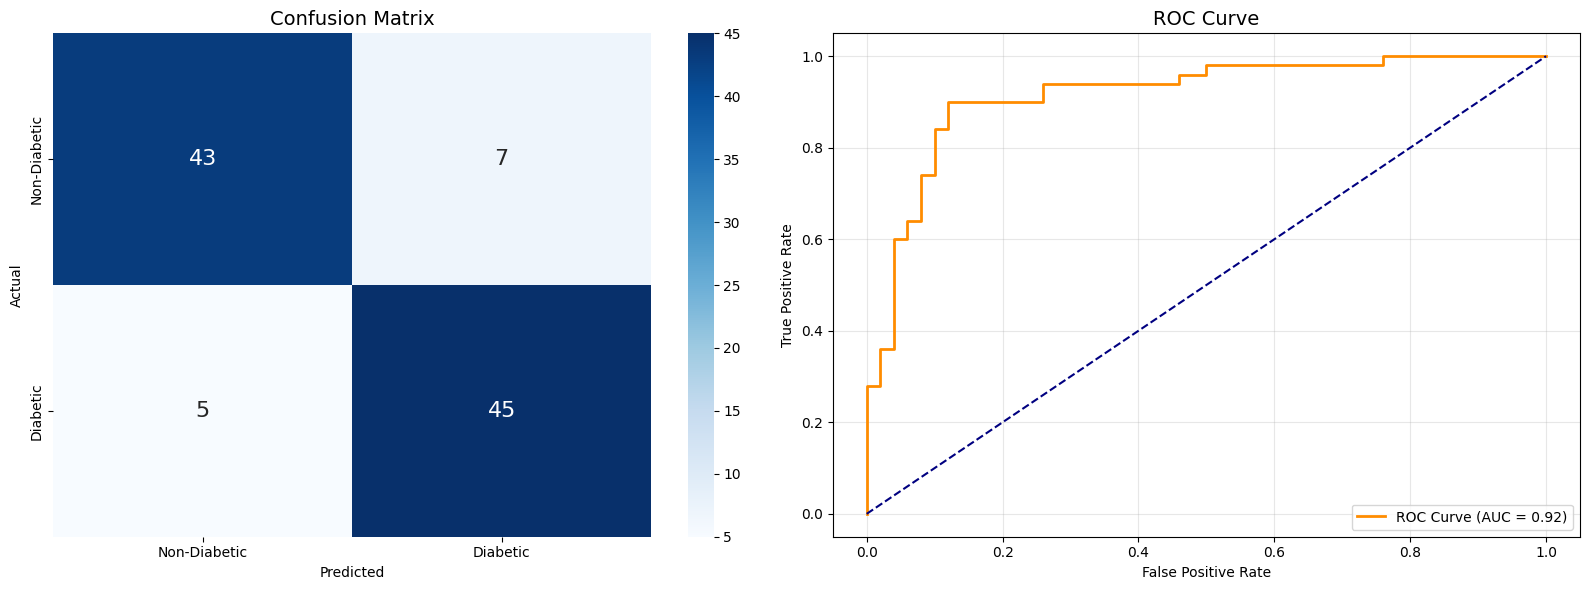


Classification Report:
              precision    recall  f1-score   support

Non-Diabetic       0.90      0.86      0.88        50
    Diabetic       0.87      0.90      0.88        50

    accuracy                           0.88       100
   macro avg       0.88      0.88      0.88       100
weighted avg       0.88      0.88      0.88       100



In [19]:
# CELL 9 — CONFUSION MATRIX AND ROC CURVE

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

y_pred_prob = final_model.predict(X_val, verbose=0).flatten()
y_pred = (y_pred_prob > 0.5).astype(int)

cm = confusion_matrix(y_val, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            ax=axes[0],
            xticklabels=['Non-Diabetic', 'Diabetic'],
            yticklabels=['Non-Diabetic', 'Diabetic'],
            annot_kws={'size': 16})
axes[0].set_title('Confusion Matrix', fontsize=14)
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

fpr, tpr, _ = roc_curve(y_val, y_pred_prob)
auc = roc_auc_score(y_val, y_pred_prob)
axes[1].plot(fpr, tpr, color='darkorange',
             lw=2, label=f'ROC Curve (AUC = {auc:.2f})')
axes[1].plot([0,1], [0,1], color='navy', linestyle='--')
axes[1].set_title('ROC Curve', fontsize=14)
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc='lower right')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('results.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nClassification Report:")
print(classification_report(y_val, y_pred,
      target_names=['Non-Diabetic', 'Diabetic']))

In [20]:
# CELL 10 — TEST SINGLE PATIENT PREDICTION

def predict_diabetes(input_dict):
    input_df = pd.DataFrame([input_dict])
    input_scaled = final_scaler.transform(input_df)
    input_cnn = input_scaled.reshape(1, input_scaled.shape[1], 1)
    prob = final_model.predict(input_cnn, verbose=0)[0][0]

    if prob < 0.3:
        risk = "Low Risk"
        advice = "You are healthy. Maintain good diet and exercise regularly."
        prob_meaning = "Low chance of diabetes"
    elif prob < 0.5:
        risk = "Medium Risk"
        advice = "Some risk detected. Monitor glucose levels regularly."
        prob_meaning = "Moderate chance of diabetes"
    elif prob < 0.7:
        risk = "High Risk"
        advice = "High risk detected. Please consult a doctor soon."
        prob_meaning = "High chance of diabetes"
    else:
        risk = "Very High Risk"
        advice = "Very high risk. Immediate medical consultation recommended."
        prob_meaning = "Very high chance of diabetes"

    print(f"{'='*45}")
    print(f"  PREDICTION  : {'Diabetic' if prob >= 0.5 else 'Non-Diabetic'}")
    print(f"  RISK LEVEL  : {risk}")
    print(f"  PROBABILITY : {prob*100:.1f}% - {prob_meaning}")
    print(f"  ADVICE      : {advice}")
    print(f"{'='*45}")

sample = {
    'Pregnancies': 6,
    'Glucose': 148,
    'BloodPressure': 72,
    'SkinThickness': 35,
    'Insulin': 0,
    'BMI': 33.6,
    'DiabetesPedigreeFunction': 0.627,
    'Age': 50
}

predict_diabetes(sample)

  PREDICTION  : Non-Diabetic
  RISK LEVEL  : Medium Risk
  PROBABILITY : 32.8% - Moderate chance of diabetes
  ADVICE      : Some risk detected. Monitor glucose levels regularly.
